In [2]:
import tensorflow as tf

MODEL_PATHS = {
    "Model A": "/kaggle/input/models/hemasakshis/comaprisons/tensorflow2/default/1/finetuned_35_layers.keras",

    "Model B": "/kaggle/input/models/hemasakshis/comaprisons/tensorflow2/default/1/finetuned_60_layers.keras",

    "Model C": "/kaggle/input/models/hemasakshis/comaprisons/tensorflow2/default/1/final_dr_model.keras",

    "Model D": "/kaggle/input/models/hemasakshis/comaprisons/tensorflow2/default/1/final_experiment_D.keras"
}

models = {}

for name, path in MODEL_PATHS.items():
    models[name] = tf.keras.models.load_model(path)
    print(f"{name} loaded successfully!")

I0000 00:00:1795017658.272406      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795017675.255801      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1795017679.373100      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model A loaded successfully!
Model B loaded successfully!
Model C loaded successfully!
Model D loaded successfully!


In [3]:
for name, model in models.items():
    print("\n", name)
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
    print("Total parameters:", model.count_params())


 Model A
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23597957

 Model B
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23597957

 Model C
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23597957

 Model D
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)
Total parameters: 23597957


In [4]:
import os

for item in os.listdir("/kaggle/input"):
    print(item)

models
competitions


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

train_df = pd.read_csv(
    "/kaggle/input/competitions/aptos2019-blindness-detection/train.csv"
)

# 70% training, 30% temporary
train_data, temp_data = train_test_split(
    train_df,
    test_size=0.30,
    stratify=train_df["diagnosis"],
    random_state=42
)

# Split remaining 30% equally into validation and test
val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["diagnosis"],
    random_state=42
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

Training images: 2563
Validation images: 549
Test images: 550


In [6]:
import tensorflow as tf
import os

IMAGE_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"

IMG_SIZE = 224
BATCH_SIZE = 32

test_data = test_data.copy()

test_data["image_path"] = test_data["id_code"].apply(
    lambda x: os.path.join(IMAGE_DIR, x + ".png")
)

def preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.keras.applications.resnet50.preprocess_input(image)
    return image, label

test_dataset = tf.data.Dataset.from_tensor_slices((
    test_data["image_path"].values,
    test_data["diagnosis"].values
))

test_dataset = (
    test_dataset
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Test dataset prepared successfully!")
print("Number of test images:", len(test_data))

Test dataset prepared successfully!
Number of test images: 550


In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

y_true = test_data["diagnosis"].values

results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    y_prob = model.predict(test_dataset, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (Macro)": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Recall (Macro)": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Weighted F1": round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 4),
        "QWK": round(cohen_kappa_score(y_true, y_pred, weights="quadratic"), 4)
    })

comparison_df = pd.DataFrame(results)

print("\nFINAL FOUR-MODEL COMPARISON")
display(comparison_df)

Evaluating Model A...
Evaluating Model B...
Evaluating Model C...
Evaluating Model D...

FINAL FOUR-MODEL COMPARISON


,Model,Test Accuracy (%),Precision (Macro),Recall (Macro),Macro F1,Weighted F1,QWK
0,Model A,77.82,0.5838,0.5847,0.5835,0.7781,0.8604
1,Model B,77.64,0.6040,0.6080,0.5940,0.7772,0.8663
2,Model C,75.82,0.5903,0.6059,0.5897,0.7641,0.8606
3,Model D,76.00,0.5801,0.5838,0.5771,0.7643,0.8403


In [8]:

import tensorflow as tf

MODEL_B_PATH = "/kaggle/input/models/hemasakshis/comaprisons/tensorflow2/default/1/finetuned_60_layers.keras"

model_b = tf.keras.models.load_model(MODEL_B_PATH)

print("Model B loaded successfully!")
print("Input shape:", model_b.input_shape)
print("Output shape:", model_b.output_shape)


Model B loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)


In [13]:

for layer in model_b.layers:
    print(layer.name, type(layer).__name__)


input_layer_1 InputLayer
resnet50 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense


In [14]:

resnet_model = model_b.get_layer("resnet50")

last_conv_layer = None

for layer in resnet_model.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer

print("Last convolutional layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)


Last convolutional layer: conv5_block3_3_conv
Output shape: (None, 7, 7, 2048)


In [15]:

grad_model = tf.keras.models.Model(
    inputs=resnet_model.input,
    outputs=resnet_model.get_layer("conv5_block3_3_conv").output
)

print("Grad-CAM target model created!")


Grad-CAM target model created!


In [16]:

gradcam_model = tf.keras.models.Model(
    inputs=model_b.input,
    outputs=[
        model_b.get_layer("resnet50").get_layer("conv5_block3_3_conv").output,
        model_b.output
    ]
)

print("Grad-CAM model created successfully!")


Grad-CAM model created successfully!


In [18]:

import numpy as np

def generate_gradcam(img_array, gradcam_model):
    img_array = tf.cast(img_array, tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = gradcam_model(img_array, training=False)
        predicted_class = tf.argmax(predictions[0])

        loss = predictions[:, predicted_class]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())

    return heatmap.numpy(), int(predicted_class.numpy()), predictions.numpy()[0]

print("Grad-CAM function defined successfully!")


Grad-CAM function defined successfully!


In [20]:

import pandas as pd
import os
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

train_data, temp_data = train_test_split(
    train_df,
    test_size=0.30,
    stratify=train_df["diagnosis"],
    random_state=42
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["diagnosis"],
    random_state=42
)

test_data = test_data.copy()

test_data["image_path"] = test_data["id_code"].apply(
    lambda x: os.path.join(DATA_DIR, "train_images", x + ".png")
)

print("Test images:", len(test_data))
print("\nProliferative DR samples:")
print(
    test_data[test_data["diagnosis"] == 4][
        ["id_code", "diagnosis", "image_path"]
    ].head()
)


Test images: 550

Proliferative DR samples:
           id_code  diagnosis  \
815   3ac3fbfca7d4          4   
469   211518c46162          4   
2034  8eeac97f02f0          4   
1763  7c90ab025331          4   
299   1638404f385c          4   

                                             image_path  
815   /kaggle/input/competitions/aptos2019-blindness...  
469   /kaggle/input/competitions/aptos2019-blindness...  
2034  /kaggle/input/competitions/aptos2019-blindness...  
1763  /kaggle/input/competitions/aptos2019-blindness...  
299   /kaggle/input/competitions/aptos2019-blindness...  


Image ID: 3ac3fbfca7d4
Actual DR Grade: 4
Input shape: (1, 224, 224, 3)


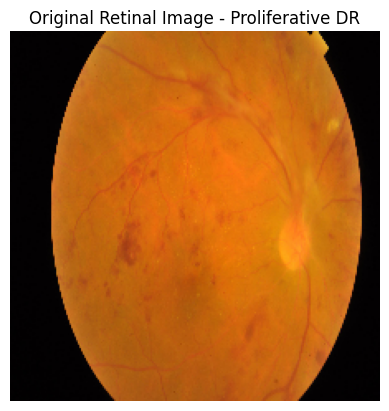

In [22]:

import matplotlib.pyplot as plt

sample_row = test_data[test_data["diagnosis"] == 4].iloc[0]

image_path = sample_row["image_path"]

image = tf.io.read_file(image_path)
image = tf.image.decode_png(image, channels=3)

original_image = tf.image.resize(image, [224, 224]).numpy().astype("uint8")

processed_image = tf.keras.applications.resnet50.preprocess_input(
    original_image.astype("float32")
)

img_array = tf.expand_dims(processed_image, axis=0)

print("Image ID:", sample_row["id_code"])
print("Actual DR Grade:", sample_row["diagnosis"])
print("Input shape:", img_array.shape)

plt.imshow(original_image)
plt.title("Original Retinal Image - Proliferative DR")
plt.axis("off")
plt.show()


In [26]:

# Get the nested ResNet50 model
resnet_model = model_b.get_layer("resnet50")

# Create a model that returns the final convolutional feature maps
feature_extractor = tf.keras.Model(
    inputs=resnet_model.input,
    outputs=resnet_model.get_layer("conv5_block3_3_conv").output
)

# Create the complete Grad-CAM model
inputs = tf.keras.Input(shape=(224, 224, 3))

features = feature_extractor(inputs)

x = resnet_model.get_layer("global_average_pooling2d")(features) if False else None


In [28]:

for layer in model_b.layers:
    print("\nLayer:", layer.name)
    print("Type:", type(layer).__name__)

    try:
        print("Input shape:", tf.nest.map_structure(lambda x: x.shape, layer.input))
    except:
        print("Input shape: Not directly available")

    try:
        print("Output shape:", tf.nest.map_structure(lambda x: x.shape, layer.output))
    except:
        print("Output shape: Not directly available")



Layer: input_layer_1
Type: InputLayer
Input shape: []
Output shape: (None, 224, 224, 3)

Layer: resnet50
Type: Functional
Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 2048)

Layer: global_average_pooling2d
Type: GlobalAveragePooling2D
Input shape: (None, 7, 7, 2048)
Output shape: (None, 2048)

Layer: dropout
Type: Dropout
Input shape: (None, 2048)
Output shape: (None, 2048)

Layer: dense
Type: Dense
Input shape: (None, 2048)
Output shape: (None, 5)


In [29]:

# Extract ResNet50 and classification layers
resnet_model = model_b.get_layer("resnet50")
gap_layer = model_b.get_layer("global_average_pooling2d")
dropout_layer = model_b.get_layer("dropout")
dense_layer = model_b.get_layer("dense")

# Input for Grad-CAM
gradcam_input = tf.keras.Input(shape=(224, 224, 3))

# Extract convolutional feature maps
feature_maps = resnet_model(gradcam_input, training=False)

# Pass through the original classification layers
x = gap_layer(feature_maps)
x = dropout_layer(x, training=False)
predictions = dense_layer(x)

# Build Grad-CAM model
gradcam_model = tf.keras.Model(
    inputs=gradcam_input,
    outputs=[feature_maps, predictions]
)

print("Corrected Grad-CAM model created!")
print("Output shapes:", [output.shape for output in gradcam_model.outputs])


Corrected Grad-CAM model created!
Output shapes: [(None, 7, 7, 2048), (None, 5)]


In [30]:

def generate_gradcam(img_array, gradcam_model):

    img_array = tf.cast(img_array, tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = gradcam_model(
            img_array, training=False
        )

        predicted_class = tf.argmax(predictions[0])
        loss = predictions[:, predicted_class]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return (
        heatmap.numpy(),
        int(predicted_class.numpy()),
        predictions.numpy()[0]
    )

print("Updated Grad-CAM function ready!")


Updated Grad-CAM function ready!


In [31]:

heatmap, predicted_class, probabilities = generate_gradcam(
    img_array,
    gradcam_model
)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("Actual class:", class_names[int(sample_row["diagnosis"])])
print("Predicted class:", class_names[predicted_class])
print(
    "Predicted probability:",
    round(float(probabilities[predicted_class]) * 100, 2),
    "%"
)
print("Heatmap shape:", heatmap.shape)


Actual class: Proliferative DR
Predicted class: Proliferative DR
Predicted probability: 55.85 %
Heatmap shape: (7, 7)


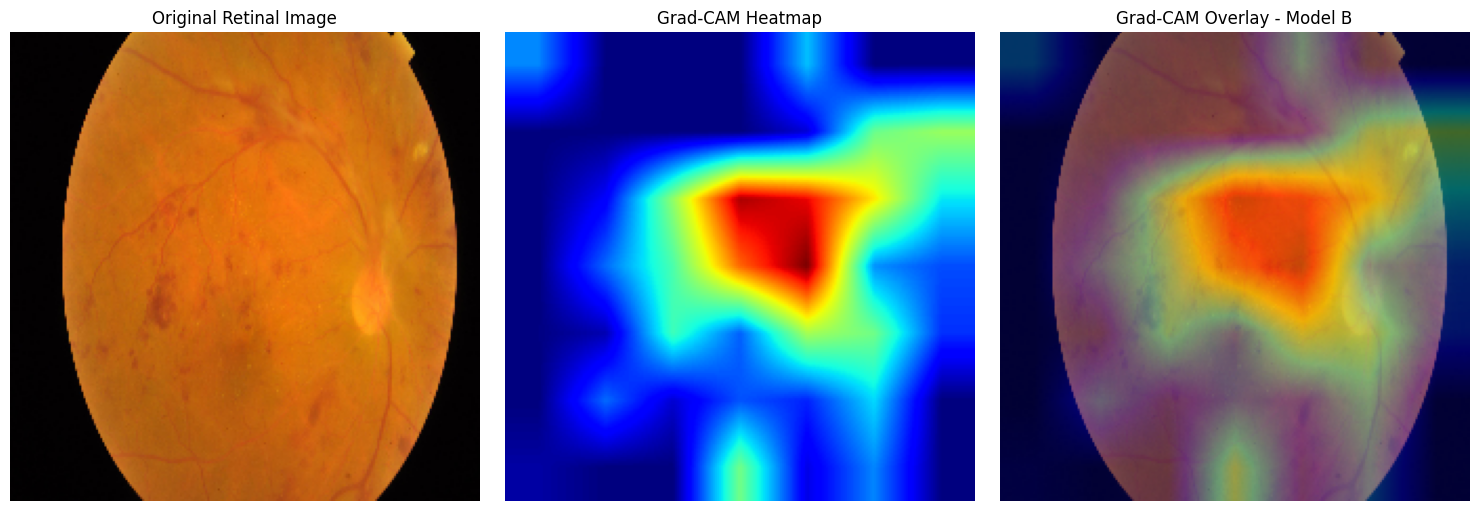

In [32]:

import cv2
import matplotlib.pyplot as plt

# Resize heatmap to original image dimensions
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Convert heatmap into a color map
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original retinal image
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Retinal Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay - Model B")
plt.axis("off")

plt.tight_layout()
plt.show()


Image ID: d9ad2a0ec026
Actual class: No DR
Input shape: (1, 224, 224, 3)


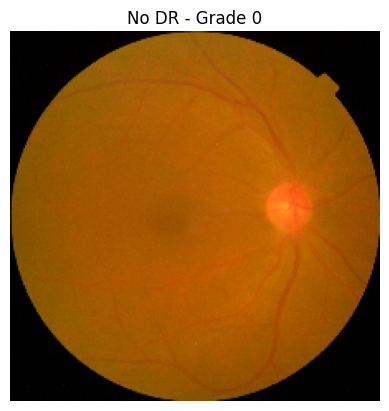

In [33]:

# Select one No DR image
sample_row = test_data[test_data["diagnosis"] == 0].iloc[0]

image_path = sample_row["image_path"]

# Load and preprocess
image = tf.io.read_file(image_path)
image = tf.image.decode_png(image, channels=3)

original_image = tf.image.resize(
    image, [224, 224]
).numpy().astype("uint8")

processed_image = tf.keras.applications.resnet50.preprocess_input(
    original_image.astype("float32")
)

img_array = tf.expand_dims(processed_image, axis=0)

print("Image ID:", sample_row["id_code"])
print("Actual class: No DR")
print("Input shape:", img_array.shape)

plt.imshow(original_image)
plt.title("No DR - Grade 0")
plt.axis("off")
plt.show()


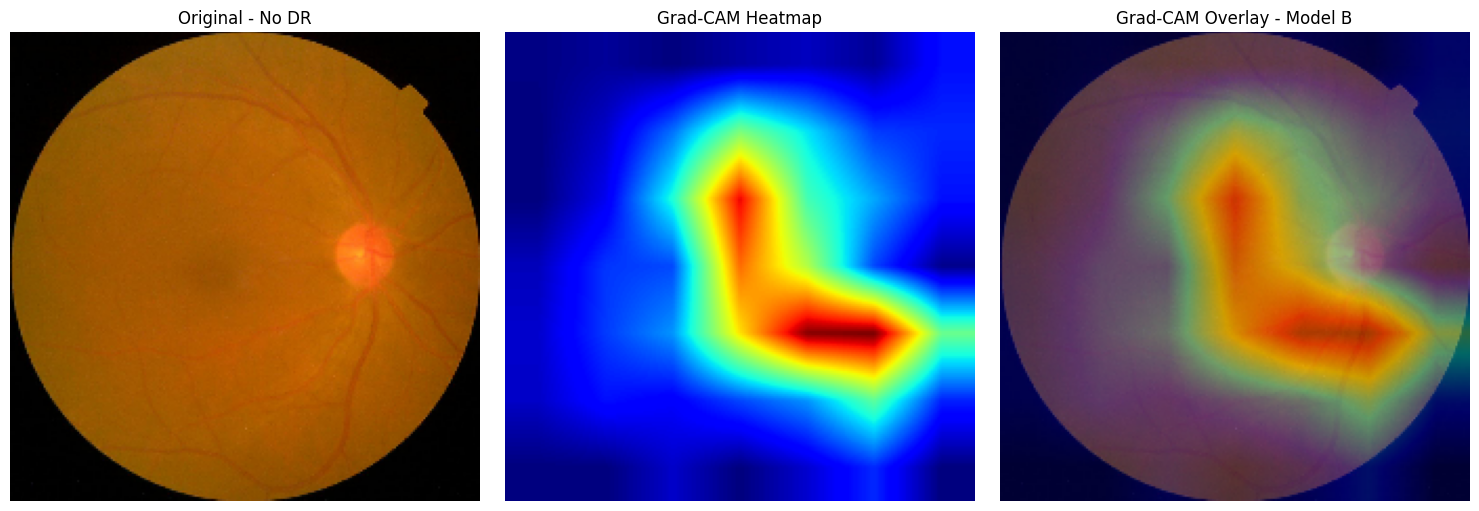

Actual class: No DR
Predicted class: No DR
Predicted probability: 99.49 %


In [34]:

# Generate Grad-CAM
heatmap, predicted_class, probabilities = generate_gradcam(
    img_array,
    gradcam_model
)

# Resize heatmap
heatmap_resized = cv2.resize(heatmap, (224, 224))

# Apply color map
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(
    heatmap_colored,
    cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_colored,
    0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original - No DR")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay - Model B")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual class:", class_names[int(sample_row["diagnosis"])])
print("Predicted class:", class_names[predicted_class])
print("Predicted probability:", round(float(probabilities[predicted_class]) * 100, 2), "%")


Image ID: ca7140ecf389
Actual class: Mild DR
Input shape: (1, 224, 224, 3)


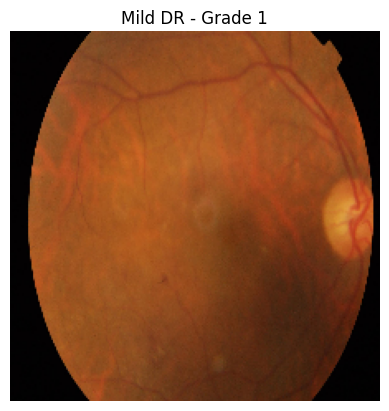

In [35]:

# Select one Mild DR image
sample_row = test_data[test_data["diagnosis"] == 1].iloc[0]

image_path = sample_row["image_path"]

# Load image
image = tf.io.read_file(image_path)
image = tf.image.decode_png(image, channels=3)

# Resize and preprocess
original_image = tf.image.resize(
    image, [224, 224]
).numpy().astype("uint8")

processed_image = tf.keras.applications.resnet50.preprocess_input(
    original_image.astype("float32")
)

img_array = tf.expand_dims(processed_image, axis=0)

print("Image ID:", sample_row["id_code"])
print("Actual class: Mild DR")
print("Input shape:", img_array.shape)

plt.imshow(original_image)
plt.title("Mild DR - Grade 1")
plt.axis("off")
plt.show()


Actual class: Mild DR
Predicted class: 2
Predicted probability: 67.12 %
Heatmap shape: (7, 7)


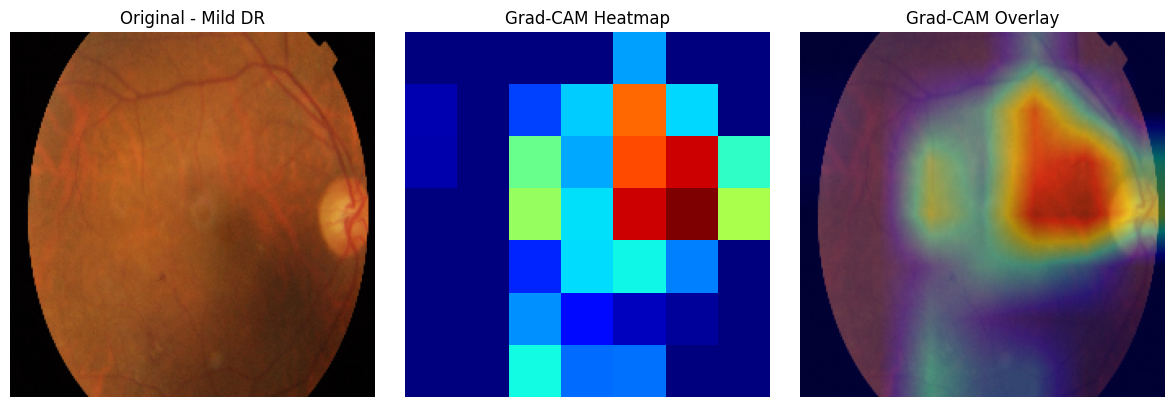

In [36]:

heatmap, predicted_class, probabilities = generate_gradcam(
    img_array, gradcam_model
)

print("Actual class: Mild DR")
print("Predicted class:", predicted_class)
print("Predicted probability:",
      round(float(probabilities[predicted_class]) * 100, 2), "%")
print("Heatmap shape:", heatmap.shape)

# Resize heatmap to match the original image
heatmap_resized = cv2.resize(heatmap, (224, 224))

# Apply color map
heatmap_colored = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)

heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    original_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original - Mild DR")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


Image ID: 89ee1fa16f90
Actual class: Moderate DR
Input shape: (1, 224, 224, 3)


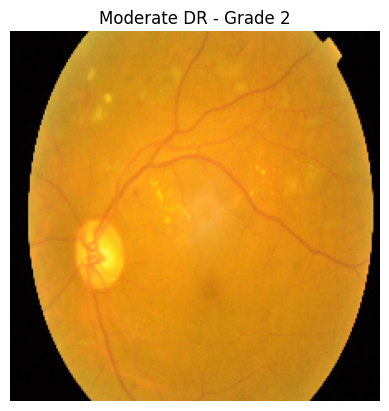

In [37]:

sample_row = test_data[test_data["diagnosis"] == 2].iloc[0]

image_path = sample_row["image_path"]

image = tf.io.read_file(image_path)
image = tf.image.decode_png(image, channels=3)

original_image = tf.image.resize(
    image, [224, 224]
).numpy().astype("uint8")

processed_image = tf.keras.applications.resnet50.preprocess_input(
    original_image.astype("float32")
)

img_array = tf.expand_dims(processed_image, axis=0)

print("Image ID:", sample_row["id_code"])
print("Actual class: Moderate DR")
print("Input shape:", img_array.shape)

plt.imshow(original_image)
plt.title("Moderate DR - Grade 2")
plt.axis("off")
plt.show()


Actual class: Moderate DR
Predicted class: 2
Predicted probability: 94.11 %
Heatmap shape: (7, 7)


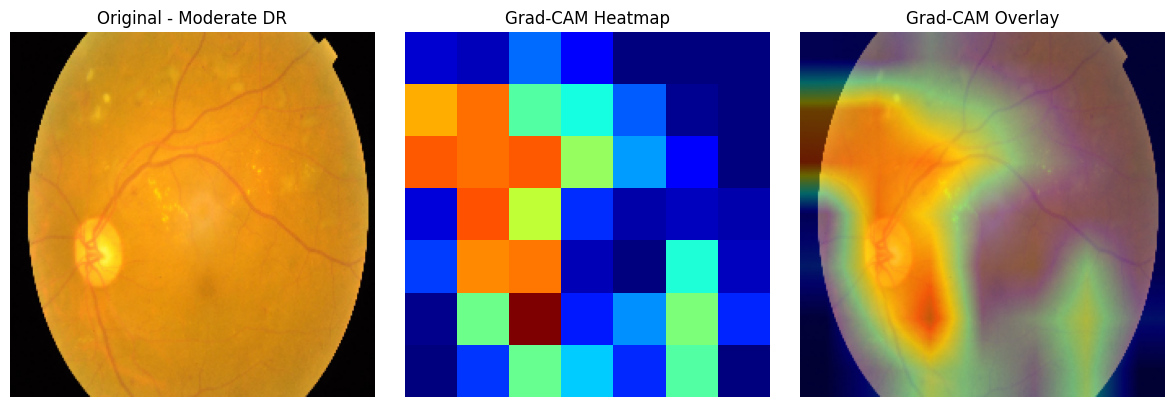

In [38]:

heatmap, predicted_class, probabilities = generate_gradcam(
    img_array, gradcam_model
)

print("Actual class: Moderate DR")
print("Predicted class:", predicted_class)
print(
    "Predicted probability:",
    round(float(probabilities[predicted_class]) * 100, 2), "%"
)
print("Heatmap shape:", heatmap.shape)

# Resize heatmap
heatmap_resized = cv2.resize(heatmap, (224, 224))

# Apply color map
heatmap_colored = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)

heatmap_colored = cv2.cvtColor(
    heatmap_colored, cv2.COLOR_BGR2RGB
)

# Create overlay
overlay = cv2.addWeighted(
    original_image, 0.6,
    heatmap_colored, 0.4, 0
)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original - Moderate DR")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


In [5]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

train_data, temp_data = train_test_split(
    train_df,
    test_size=0.30,
    stratify=train_df["diagnosis"],
    random_state=42
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["diagnosis"],
    random_state=42
)

test_data = test_data.copy()

test_data["image_path"] = test_data["id_code"].apply(
    lambda x: os.path.join(DATA_DIR, "train_images", x + ".png")
)

print("Test dataset recreated:", len(test_data))


Test dataset recreated: 550


In [8]:

print("CSV shape:", train_df.shape)
print("CSV columns:", train_df.columns.tolist())

print("\nFirst 5 image IDs:")
print(train_df["id_code"].head())

print("\nSearching for image ID:")
print(train_df[
    train_df["id_code"].astype(str).str.contains("009245722fa4", na=False)
])

print("\nDoes the image file exist?")
print(os.path.exists(
    os.path.join(DATA_DIR, "train_images", "009245722fa4.png")
))


CSV shape: (3662, 2)
CSV columns: ['id_code', 'diagnosis']

First 5 image IDs:
0    000c1434d8d7
1    001639a390f0
2    0024cdab0c1e
3    002c21358ce6
4    005b95c28852
Name: id_code, dtype: object

Searching for image ID:
Empty DataFrame
Columns: [id_code, diagnosis]
Index: []

Does the image file exist?
False


In [7]:

image_id = "009245722fa4"

row = train_df[train_df["id_code"] == image_id]

if not row.empty:
    image_path = os.path.join(
        DATA_DIR, "train_images", image_id + ".png"
    )

    print("Image ID:", image_id)
    print("Actual diagnosis:", int(row.iloc[0]["diagnosis"]))
    print("Image exists:", os.path.exists(image_path))
    print("Image path:", image_path)
else:
    print("Image ID not found in train.csv")


Image ID not found in train.csv


In [6]:

image_id = "009245722fa4"

row = test_data[test_data["id_code"] == image_id]

if not row.empty:
    image_path = row.iloc[0]["image_path"]
    print("Image path:", image_path)
    print("Actual diagnosis:", row.iloc[0]["diagnosis"])
    print("File exists:", os.path.exists(image_path))
else:
    print("Image not found in test_data")


Image not found in test_data


In [9]:

sample_row = test_data.iloc[0]

print("Image ID:", sample_row["id_code"])
print("Actual diagnosis:", sample_row["diagnosis"])
print("Image path:", sample_row["image_path"])
print("File exists:", os.path.exists(sample_row["image_path"]))


Image ID: 89ee1fa16f90
Actual diagnosis: 2
Image path: /kaggle/input/competitions/aptos2019-blindness-detection/train_images/89ee1fa16f90.png
File exists: True


In [10]:

# Select one image from the test dataset
sample_row = test_data.iloc[0]

# Get its original image ID
image_id = sample_row["id_code"]

# Get its actual diagnosis
actual_grade = int(sample_row["diagnosis"])

# Get its image path
image_path = sample_row["image_path"]

print("Image ID:", image_id)
print("Actual Diagnosis:", actual_grade)
print("Image Path:", image_path)
print("Image Exists:", os.path.exists(image_path))


Image ID: 89ee1fa16f90
Actual Diagnosis: 2
Image Path: /kaggle/input/competitions/aptos2019-blindness-detection/train_images/89ee1fa16f90.png
Image Exists: True


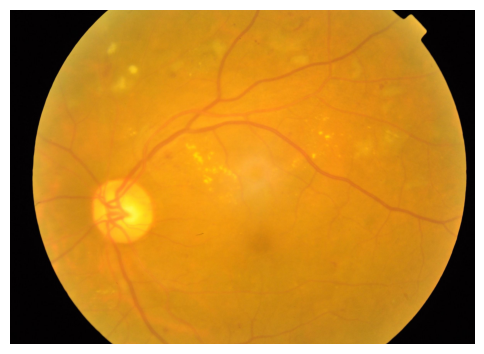

In [11]:

from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(image_path)
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.show()


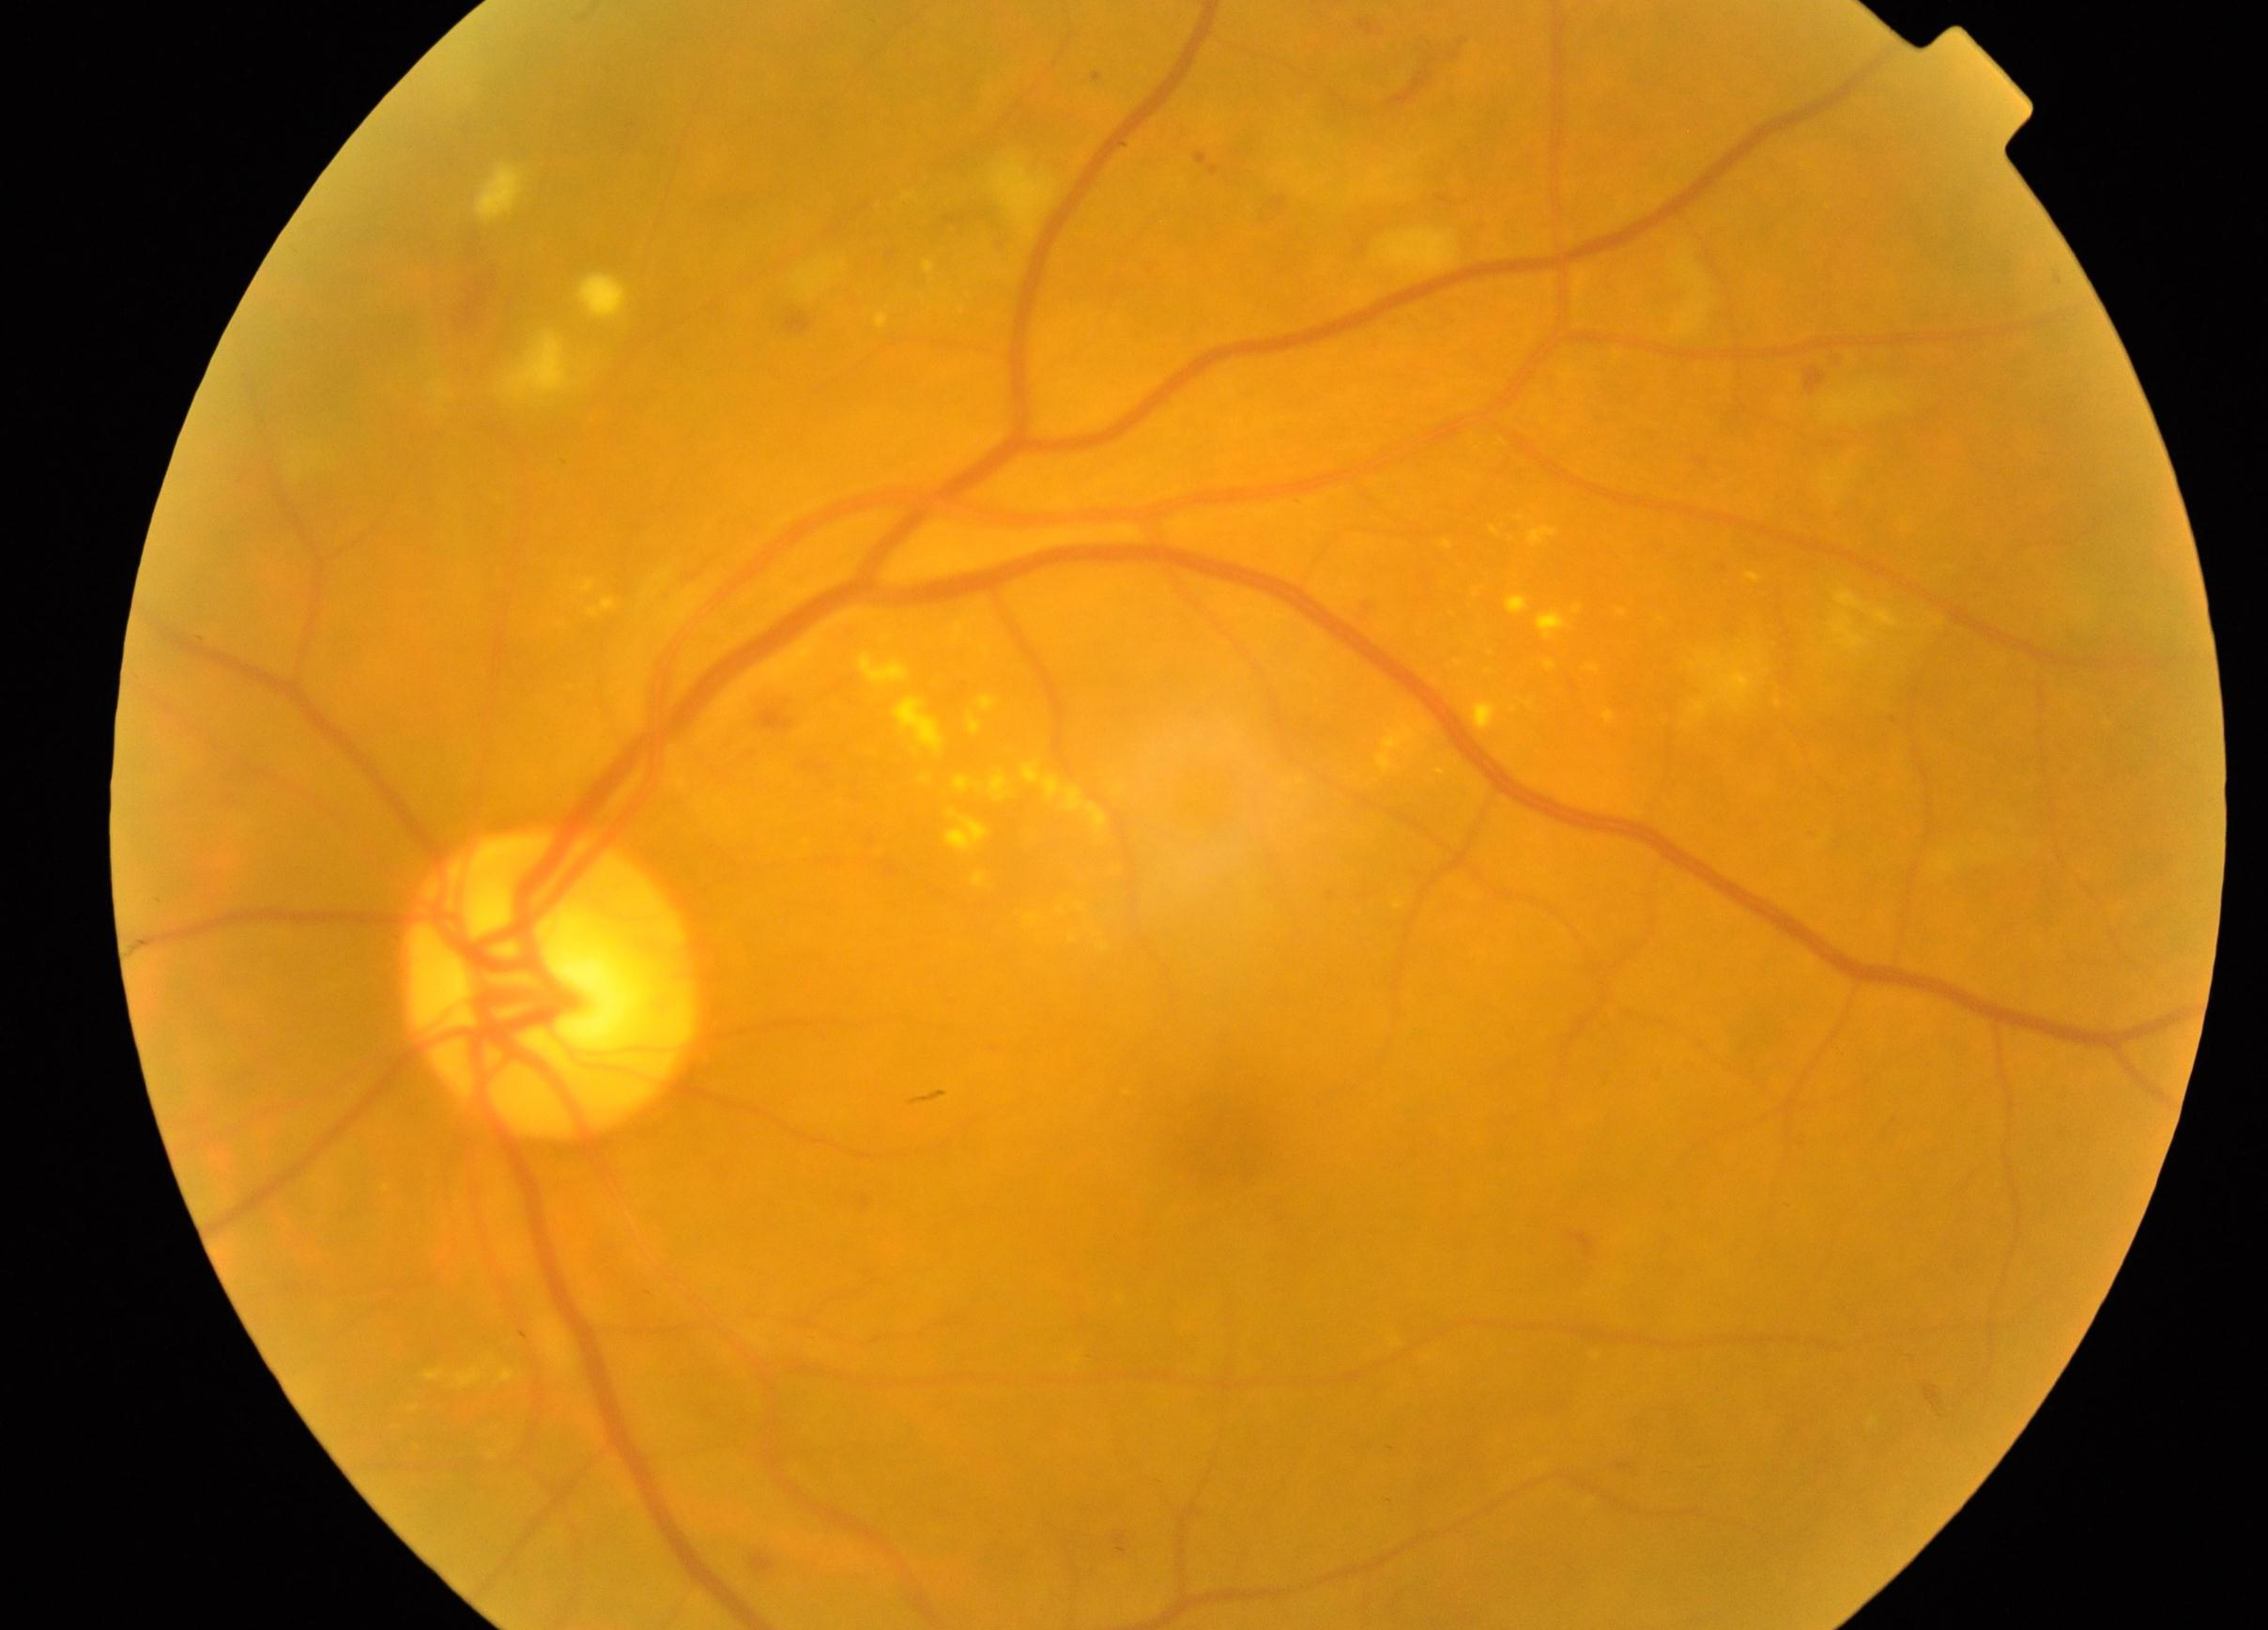

In [13]:

from IPython.display import display, Image

display(Image(filename=image_path))


In [14]:

from IPython.display import FileLink, display
import shutil

shutil.copy(image_path, "/kaggle/working/89ee1fa16f90.png")

display(FileLink("/kaggle/working/89ee1fa16f90.png"))


/kaggle/working/89ee1fa16f90.png